# 01. Explore CSV datasets

Inspect the three source datasets, diagnose the FronkonGames header issue, and prepare Steam App IDs for comparison with SteamIDX.

## 1. Setup

In [ ]:
import csv, re

import numpy as np
import pandas as pd

from video_game_retention.config import PROJECT_ROOT
pd.set_option("display.max_columns", None)

## 2. Load the CSV datasets

Load the three source datasets and inspect their dimensions.

In [ ]:
tamber_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/raw/tamber_steam-video-games.csv",
    header=None,
    names=["user_id", "game_title", "behavior", "value", "extra"],
)

rabieel_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/raw/rabieelkharoua_online-gaming-behavior-dataset.csv"
)

In [ ]:
fronkon_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/raw/games.csv",
    index_col=False
)

In [ ]:
print("Tamber:", tamber_df.shape)
print("Rabieelkharoua:", rabieel_df.shape)
print("FronkonGames:", fronkon_df.shape)

## 3. Preview the datasets

In [ ]:
tamber_df.head()

In [ ]:
rabieel_df.head()

In [ ]:
fronkon_df.head()

## 4. Investigate the FronkonGames CSV header

In [ ]:
fronkon_df.info()

The initial preview suggests that some values are misaligned with their column names. Inspect the raw CSV header and first record to identify the cause.

In [ ]:
csv_path = f"{PROJECT_ROOT}/data/raw/games.csv"

with open(csv_path, encoding="utf-8", newline="") as f:
    reader = csv.reader(f)

    header = next(reader)
    first_row = next(reader)

print("Header columns:", len(header))
print("First row values:", len(first_row))

In [ ]:
for i, value in enumerate(first_row):
    column = header[i] if i < len(header) else "EXTRA COLUMN"
    print(f"{i}: {column} -> {str(value)[:60]}")

The header appears to combine `Discount` and `DLC count` into one field. Split the header into two columns before reloading the CSV.

In [ ]:
corrected_header = header[:7] + ["Discount", "DLC count"] + header[8:]

fronkon_df = pd.read_csv(
    csv_path, header=0, names=corrected_header, index_col=False
)

In [ ]:
fronkon_df.head()

In [ ]:
fronkon_df.info()

## 5. Explore the corrected game metadata

Inspect Metacritic scores and locate Grand Theft Auto V Legacy by App ID and name.

In [ ]:
fronkon_df.sort_values(by="Metacritic score", ascending=False).head(5)

In [ ]:
fronkon_df.loc[fronkon_df["AppID"] == 271590].head()

In [ ]:
fronkon_df[fronkon_df["Metacritic score"] == 96]

In [ ]:
fronkon_df.loc[
    fronkon_df["Name"].str.contains("Grand Theft Auto V Legacy", case=False, na=False),
    ["AppID", "Name"],
]

## 6. Extract unique Steam App IDs

Convert IDs to numeric values, discard missing or infinite values, and remove duplicates.

In [ ]:
fronkon_ids = (
    pd.to_numeric(fronkon_df["AppID"], errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .astype(int)
    .drop_duplicates()
    .tolist()
)

print(fronkon_ids[:10])

In [ ]:
len(fronkon_ids)

## Genre and Category

In [ ]:
df = pd.read_csv(
    f"{PROJECT_ROOT}/data/semi_processed/steamidx_games.csv"
)

column =  ["Genres", "Categories"]

In [33]:
import pandas as pd
import re

def clean_attributes(row):
    attributes = set()

    for value in row.dropna():
        for term in str(value).split(","):
            term = term.lower().strip()
            term = re.sub(r"\s+", " ", term)

            if term not in {
                "", "na", "nan", "null",
                "none", "n/a"
            }:
                attributes.add(term)

    return sorted(attributes)

df["Game_Attributes"] = df[
    ["Genres", "Categories"]
].apply(clean_attributes, axis=1)

In [34]:
attributes = (
    df["Game_Attributes"]
    .explode()
    .dropna()
    .unique()
    .tolist()
)

In [35]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = model.encode(
    attributes,
    normalize_embeddings=True
)

c:\Users\Richa\Desktop\work\illinois_tech\ds_grad\first_year\fall_2026\csp_571\assignments\csp_571_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Richa\Desktop\work\illinois_tech\ds_grad\first_year\fall_2026\csp_571\assignments\csp_571_project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Richa\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingfa

In [36]:
from sklearn.metrics.pairwise import cosine_similarity

similarity = cosine_similarity(embeddings)

similarity_df = pd.DataFrame(
    similarity,
    index=attributes,
    columns=attributes
)

similarity_df.head()

,action,color alternatives,custom volume controls,family sharing,keyboard only option,multi-player,online pvp,pvp,shared/split screen pvp,stereo sound,...,game development,touch only option,narrated game menus,#category_playable_at_your_own_pace,vr only,education,software training,#category_contrast_controls,#category_playable_without_vision,game demo
action,1.000000,0.117115,0.016396,0.178296,0.137510,0.234132,0.173227,0.270771,0.044090,0.220001,...,0.304006,0.183366,0.219573,0.221154,0.213635,0.350508,0.155638,0.121883,0.248357,0.351003
color alternatives,0.117115,1.000000,0.184104,0.074459,0.153768,0.171379,0.117590,0.128132,0.096306,0.142503,...,0.149642,0.153498,0.107441,0.038777,0.203237,0.058095,0.075131,0.318068,0.136839,0.144086
custom volume controls,0.016396,0.184104,1.000000,-0.013351,0.146261,0.150002,0.105262,0.101473,0.171342,0.299886,...,0.031620,0.105130,0.191922,0.036795,0.108615,-0.079750,0.037480,0.277960,0.040599,0.112137
family sharing,0.178296,0.074459,-0.013351,1.000000,0.013657,0.189149,0.154873,0.194166,0.262584,0.124365,...,0.112519,0.080083,0.119286,0.126059,0.192795,0.261619,0.069214,0.045763,0.008840,0.091713
keyboard only option,0.137510,0.153768,0.146261,0.013657,1.000000,0.088508,0.034765,0.052815,0.033272,0.095778,...,0.029053,0.523830,0.108737,0.093921,0.216521,0.085367,-0.019746,0.133861,0.152605,0.088653


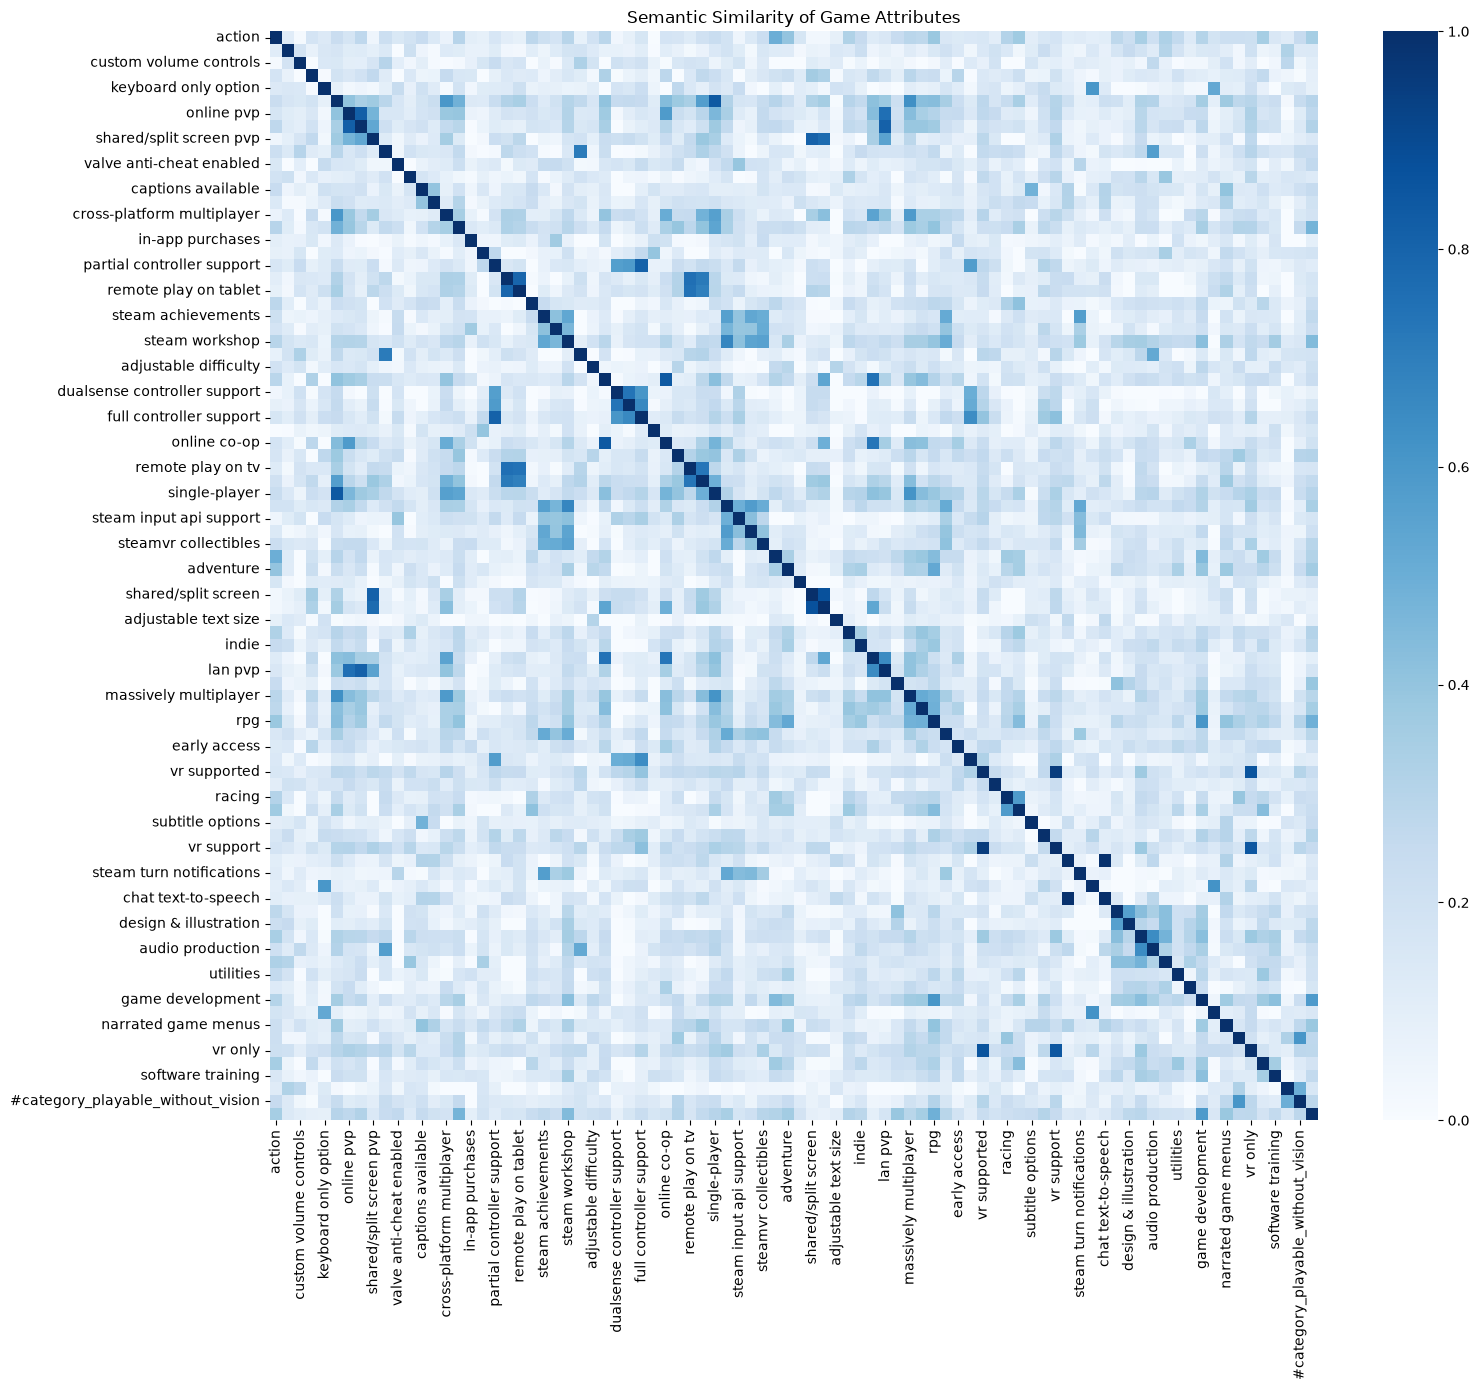

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 14))

sns.heatmap(
    similarity_df,
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Semantic Similarity of Game Attributes")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.cluster import AgglomerativeClustering

N_CLUSTERS = 20

clustering = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    metric="cosine",
    linkage="average"
)

clusters = clustering.fit_predict(embeddings)

In [41]:
attribute_clusters = pd.DataFrame({
    "Attribute": attributes,
    "Cluster": clusters
})

cluster_summary = (
    attribute_clusters
    .groupby("Cluster")["Attribute"]
    .apply(list)
    .reset_index()
)

cluster_summary

,Cluster,Attribute
0,0,"[simulation, animation & modeling, design & il..."
1,1,"[action, stats, strategy, adventure, casual, i..."
2,2,"[family sharing, multi-player, online pvp, pvp..."
3,3,"[early access, hdr available]"
4,4,"[includes level editor, includes source sdk]"
5,5,"[partial controller support, dualsense control..."
6,6,"[captions available, commentary available, sub..."
7,7,"[stereo sound, surround sound, vr supported, v..."
8,8,"[adjustable difficulty, adjustable text size]"
9,9,[in-app purchases]


## 2

In [42]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MultiLabelBinarizer

In [ ]:
df = pd.read_csv(
    f"{PROJECT_ROOT}/data/semi_processed/steamidx_games.csv"
)

In [44]:
def clean_attributes(value):
    if pd.isna(value):
        return []

    attributes = set()

    for term in str(value).split(","):
        term = term.lower().strip()
        term = re.sub(r"\s+", " ", term)

        if term not in {
            "", "na", "nan", "null",
            "none", "n/a"
        }:
            attributes.add(term)

    return sorted(attributes)

In [45]:
df = df.drop(columns=["Tags"], errors="ignore")

df["Genres_Clean"] = df["Genres"].apply(
    clean_attributes
)

df["Categories_Clean"] = df["Categories"].apply(
    clean_attributes
)

In [46]:
genres = sorted(
    df["Genres_Clean"]
    .explode()
    .dropna()
    .unique()
)

categories = sorted(
    df["Categories_Clean"]
    .explode()
    .dropna()
    .unique()
)

print("Unique genres:", len(genres))
print("Unique categories:", len(categories))

Unique genres: 22
Unique categories: 64


In [47]:
model = SentenceTransformer("all-MiniLM-L6-v2")

genre_embeddings = model.encode(
    [f"Video game genre: {term}" for term in genres],
    normalize_embeddings=True
)

category_embeddings = model.encode(
    [f"Video game feature: {term}" for term in categories],
    normalize_embeddings=True
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4048.14it/s]


In [48]:
genre_similarity = pd.DataFrame(
    cosine_similarity(genre_embeddings),
    index=genres,
    columns=genres
)

category_similarity = pd.DataFrame(
    cosine_similarity(category_embeddings),
    index=categories,
    columns=categories
)

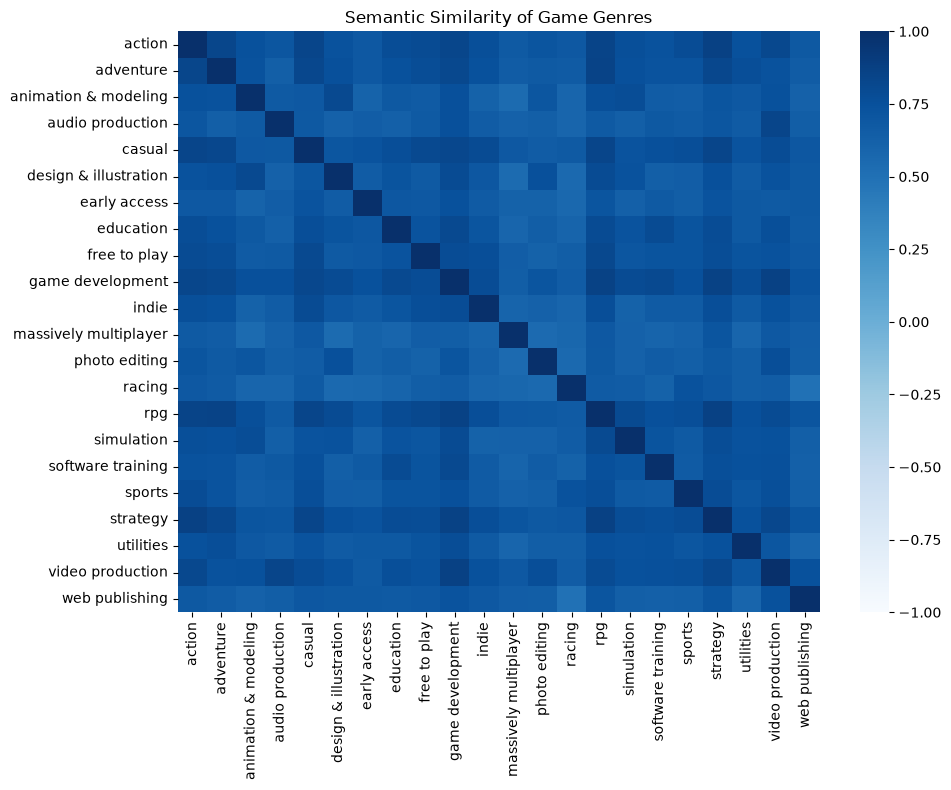

In [49]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    genre_similarity,
    cmap="Blues",
    vmin=-1,
    vmax=1
)

plt.title("Semantic Similarity of Game Genres")
plt.tight_layout()
plt.show()

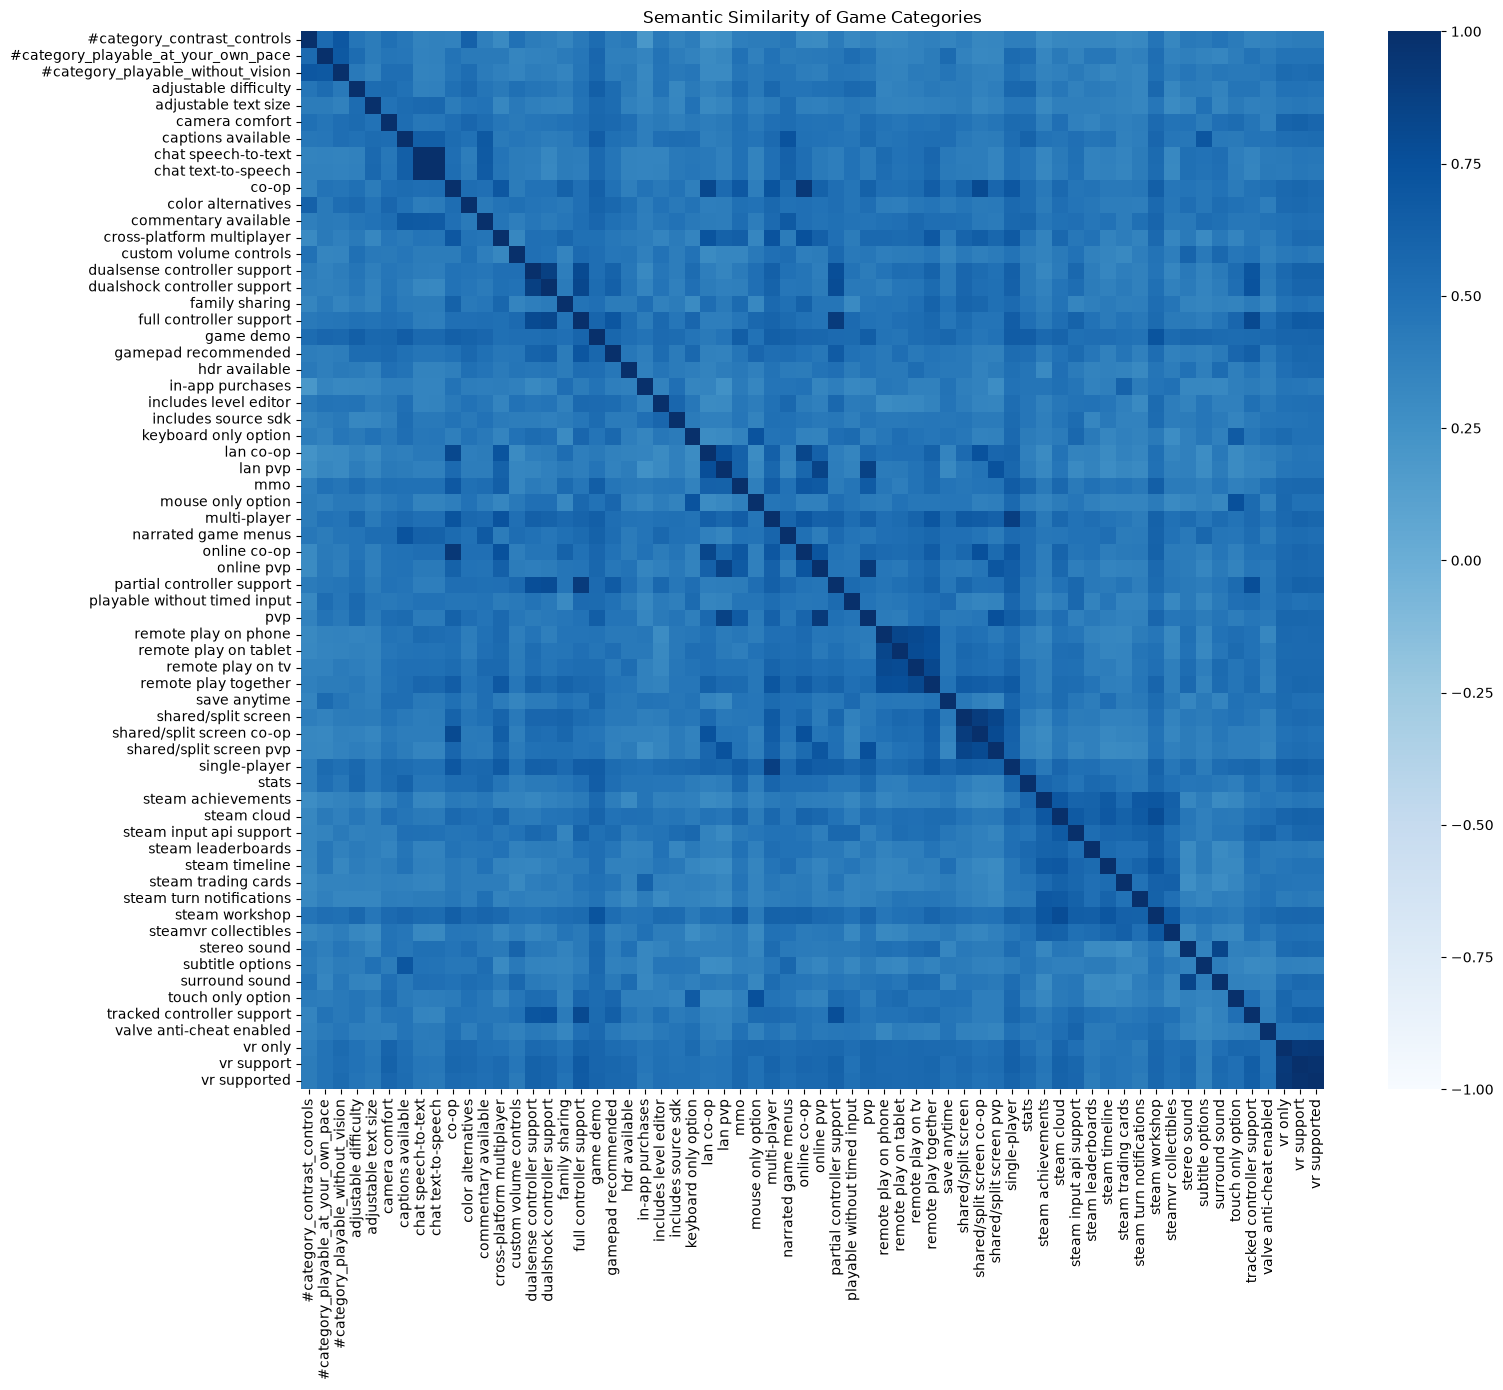

In [50]:
plt.figure(figsize=(16, 14))

sns.heatmap(
    category_similarity,
    cmap="Blues",
    vmin=-1,
    vmax=1
)

plt.title("Semantic Similarity of Game Categories")
plt.tight_layout()
plt.show()

In [51]:
def evaluate_clusters(embeddings, max_clusters=20):
    results = []

    upper_limit = min(
        max_clusters,
        len(embeddings) - 1
    )

    for k in range(2, upper_limit + 1):

        clustering = AgglomerativeClustering(
            n_clusters=k,
            metric="cosine",
            linkage="average"
        )

        labels = clustering.fit_predict(embeddings)

        score = silhouette_score(
            embeddings,
            labels,
            metric="cosine"
        )

        results.append({
            "Clusters": k,
            "Silhouette": score
        })

    return pd.DataFrame(results)

In [61]:
genre_scores = evaluate_clusters(
    genre_embeddings,
    max_clusters=20
)

category_scores = evaluate_clusters(
    category_embeddings,
    max_clusters=25
)

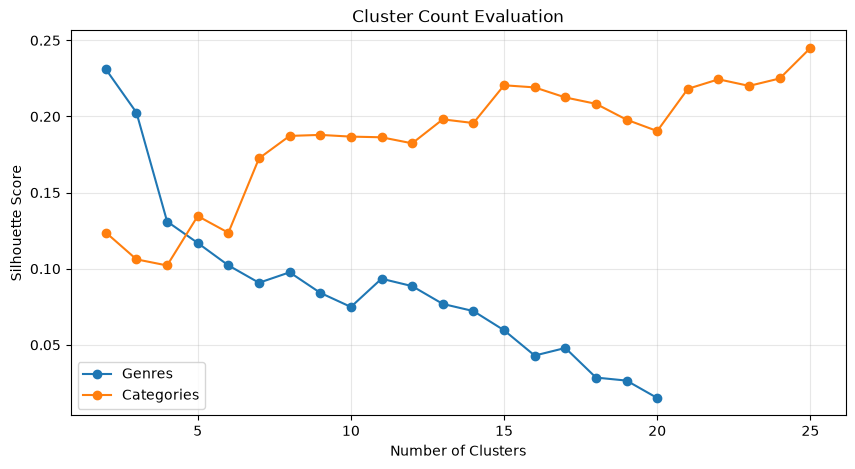

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(
    genre_scores["Clusters"],
    genre_scores["Silhouette"],
    marker="o",
    label="Genres"
)

plt.plot(
    category_scores["Clusters"],
    category_scores["Silhouette"],
    marker="o",
    label="Categories"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Cluster Count Evaluation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [63]:


N_CATEGORY_CLUSTERS = int(
    category_scores.loc[
        category_scores["Silhouette"].idxmax(),
        "Clusters"
    ]
)


print("Category clusters:", N_CATEGORY_CLUSTERS)

Category clusters: 25


In [78]:
genre_model = AgglomerativeClustering(
    n_clusters=17,
    metric="cosine",
    linkage="average"
)

category_model = AgglomerativeClustering(
    n_clusters=15,
    metric="cosine",
    linkage="average"
)

genre_labels = genre_model.fit_predict(
    genre_embeddings
)

category_labels = category_model.fit_predict(
    category_embeddings
)

In [76]:
genre_clusters = pd.DataFrame({
    "Attribute": genres,
    "Cluster": genre_labels
})

category_clusters = pd.DataFrame({
    "Attribute": categories,
    "Cluster": category_labels
})

In [77]:
genre_summary = (
    genre_clusters
    .groupby("Cluster")["Attribute"]
    .apply(list)
    .reset_index()
)

category_summary = (
    category_clusters
    .groupby("Cluster")["Attribute"]
    .apply(list)
    .reset_index()
)

display(genre_summary)
display(category_summary)

,Cluster,Attribute
0,0,"[action, adventure, casual, rpg, strategy]"
1,1,"[game development, video production]"
2,2,[simulation]
3,3,[web publishing]
4,4,[sports]
5,5,[racing]
6,6,[free to play]
7,7,[utilities]
8,8,[design & illustration]
9,9,[photo editing]


,Cluster,Attribute
0,0,"[camera comfort, vr only, vr support, vr suppo..."
1,1,"[adjustable difficulty, game demo, stats]"
2,2,"[#category_contrast_controls, #category_playab..."
3,3,"[co-op, cross-platform multiplayer, lan co-op,..."
4,4,"[steam trading cards, steamvr collectibles]"
5,5,"[steam achievements, steam cloud, steam input ..."
6,6,"[remote play on phone, remote play on tablet, ..."
7,7,[playable without timed input]
8,8,"[stereo sound, surround sound]"
9,9,"[dualsense controller support, dualshock contr..."
